# Regression Notebook

**Part 1:** Simple Linear Regression on `Study_vs_Score_data.csv` (Attendance Hours -> Final Marks)

**Part 2:** Multiple Linear Regression on `Student_Performance_1_.csv` (multiple features -> Performance Index)

## Part 1: Simple Linear Regression
### Attendance Hours vs Final Marks

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sb
from sklearn import linear_model, metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
%matplotlib inline

In [2]:
df1 = pd.read_csv("Study_vs_Score_data.csv")
print(df1.shape)
print(df1.info())
df1.head()

(1000, 2)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Attendance_Hours  1000 non-null   float64
 1   Final_Marks       1000 non-null   float64
dtypes: float64(2)
memory usage: 15.8 KB
None


,Attendance_Hours,Final_Marks
0,36.217808,58.997409
1,76.550001,71.598279
2,61.239576,72.520777
3,51.906094,69.005976
4,20.921305,53.259605


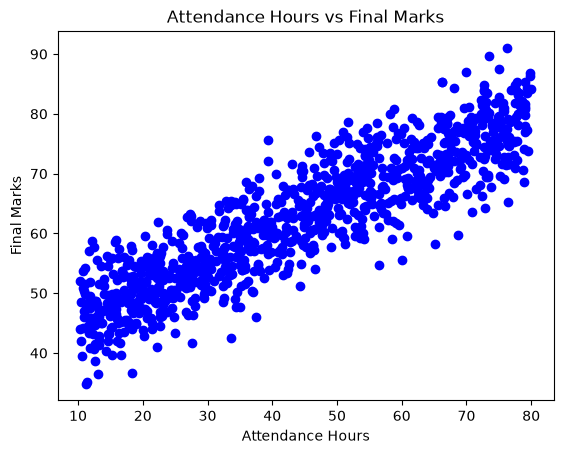

In [3]:
# Scatter plot of the raw data
plt.scatter(df1['Attendance_Hours'], df1['Final_Marks'], color='blue')
plt.title("Attendance Hours vs Final Marks")
plt.xlabel("Attendance Hours")
plt.ylabel("Final Marks")
plt.show()

<Axes: >

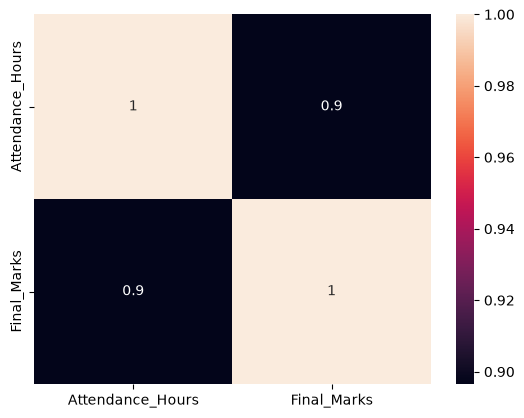

In [4]:
# Correlation
data_corr = df1.corr()
sb.heatmap(data_corr, annot=True)

In [5]:
# Train/test split
train_x, test_x, train_y, test_y = train_test_split(
    df1[['Attendance_Hours']], df1[['Final_Marks']], test_size=0.30, random_state=42
)

regress1 = linear_model.LinearRegression()
regress1.fit(train_x, train_y)

# The coefficients
print('Coefficients: ', regress1.coef_)
print('Intercept: ', regress1.intercept_)

Coefficients:  [[0.48739895]]
Intercept:  [41.16496495]


/home/andromeda/Documents/code/homework/ml/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


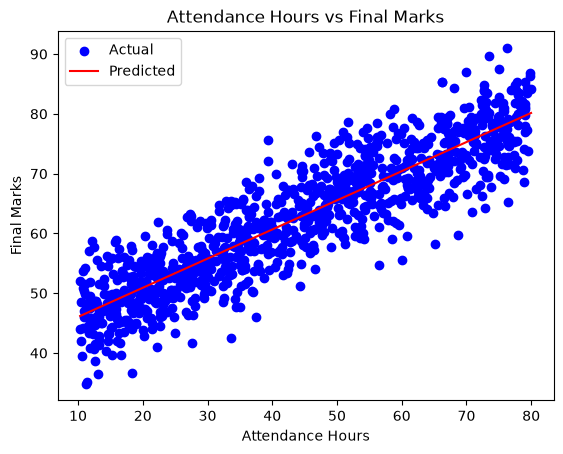

In [6]:
# Regression line over the data
plt.scatter(df1['Attendance_Hours'], df1['Final_Marks'], color='blue', label="Actual")
x_range = np.linspace(df1['Attendance_Hours'].min(), df1['Attendance_Hours'].max(), 100).reshape(-1, 1)
plt.plot(x_range, regress1.predict(x_range), '-r', label="Predicted")
plt.title("Attendance Hours vs Final Marks")
plt.xlabel("Attendance Hours")
plt.ylabel("Final Marks")
plt.legend()
plt.show()

In [7]:
# Predictions on the test set
y_predicted1 = regress1.predict(test_x)

print("Actual vs Predicted")
for actual, predicted in zip(test_y.values, y_predicted1):
    print(actual, predicted)

Actual vs Predicted
[63.29139173] [59.03416073]
[76.7350388] [73.89963416]
[67.29896098] [61.8246294]
[60.77779175] [58.1882364]
[71.58204137] [78.45309887]
[85.38022894] [79.1152755]
[54.07966173] [61.81967993]
[79.50469] [75.58725863]
[41.96213781] [48.28079699]
[66.19715431] [63.73901478]
[59.75468061] [74.66041776]
[67.83268427] [72.3530995]
[63.92666995] [64.21075123]
[43.36974877] [53.3722745]
[52.66854699] [50.05637725]
[45.83469702] [48.95632823]
[80.00868052] [76.40409134]
[45.60469043] [49.59092341]
[64.77153036] [56.67426507]
[55.49094382] [54.57672327]
[75.03078736] [72.38885662]
[67.17029177] [68.05091233]
[34.87081333] [46.66064536]
[54.52365253] [55.36703685]
[65.24759667] [64.76061358]
[71.27537795] [70.68752266]
[64.62002053] [67.75195813]
[79.94879746] [69.52581686]
[46.83173092] [52.2291553]
[80.54094146] [76.74572438]
[68.74145511] [67.70703299]
[79.98282286] [79.19414418]
[55.01049008] [53.18151929]
[77.97179374] [79.6864202]
[43.5702683] [49.4772909]
[68.12851073]

In [8]:
# Metrics (test data)
print('Mean Absolute Error:', metrics.mean_absolute_error(test_y, y_predicted1))
print('Mean Squared Error:', metrics.mean_squared_error(test_y, y_predicted1))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(test_y, y_predicted1)))
print('R2 Score:', r2_score(test_y, y_predicted1))

Mean Absolute Error: 3.7383939108644526
Mean Squared Error: 22.591227941642163
Root Mean Squared Error: 4.7530230318863556
R2 Score: 0.8144646586719524


## Part 2: Multiple Linear Regression
### Predicting Performance Index

In [9]:
df2 = pd.read_csv("Student_Performance_1_.csv")
print(df2.shape)
print(df2.info())
df2.head()

(10000, 6)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 468.9 KB
None


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [10]:
# Encode the categorical column (Yes/No -> 1/0)
df2['Extracurricular Activities'] = df2['Extracurricular Activities'].replace(['Yes', 'No'], [1, 0])
df2.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


<Axes: >

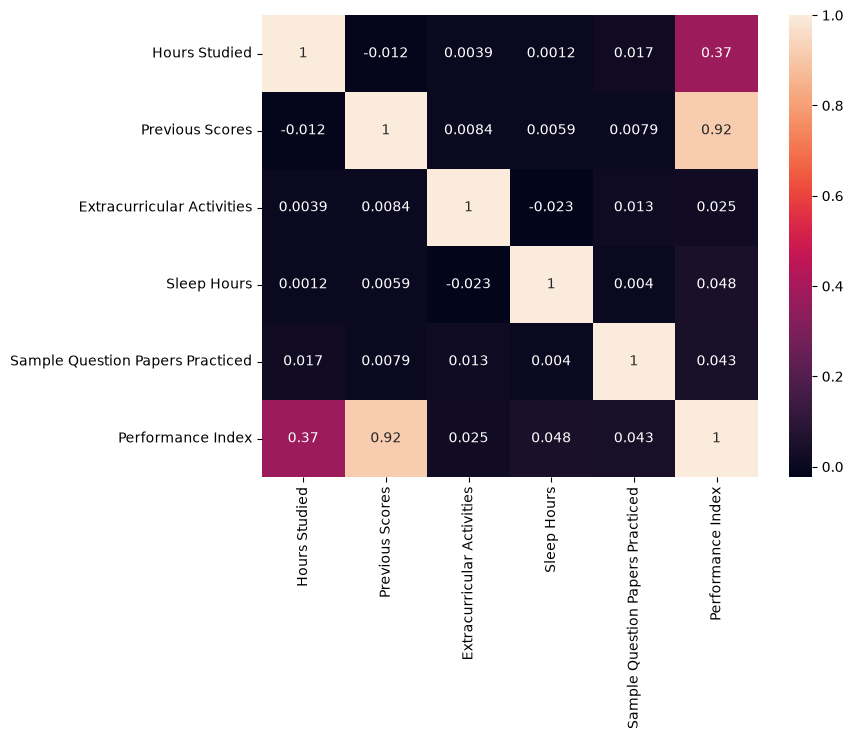

In [11]:
# Correlation
plt.figure(figsize=(8, 6))
sb.heatmap(df2.corr(), annot=True)

In [12]:
# Input / output split
features = ['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
            'Sleep Hours', 'Sample Question Papers Practiced']
X = df2[features]
y = df2['Performance Index']

train_x, test_x, train_y, test_y = train_test_split(X, y, test_size=0.30, random_state=42)

In [13]:
regress2 = linear_model.LinearRegression()
regress2.fit(train_x, train_y)

# The coefficients
print('Coefficients: ', regress2.coef_)
print('Intercept: ', regress2.intercept_)

Coefficients:  [2.85895223 1.01551979 0.58171285 0.47967676 0.19039416]
Intercept:  -33.836543807141744


In [14]:
# Predictions on the test set
y_predicted2 = regress2.predict(test_x)

print("Actual vs Predicted")
for actual, predicted in zip(test_y.values, y_predicted2):
    print(actual, predicted)

Actual vs Predicted
51.0 54.7472855429907
20.0 22.618844337002862
46.0 47.936651242300776
28.0 31.340098651561156
41.0 43.05974288236232
59.0 59.123239442840664
48.0 45.92365148898836
87.0 86.456919761862
37.0 37.770922914897874
73.0 72.0625658740102
66.0 63.5418754570937
30.0 24.903827093665058
61.0 60.837039729851334
45.0 44.026839782308706
52.0 49.05384648751464
41.0 44.629723121043305
63.0 58.00104776386534
78.0 78.99704138427805
63.0 65.71465237830805
42.0 46.66621000417884
59.0 62.486059851522604
15.0 15.45863523500401
38.0 38.43820682705563
76.0 76.83141327037461
84.0 84.05562224470691
32.0 31.095473662678764
30.0 28.689219769421122
92.0 88.83934288020905
52.0 51.143839354954586
57.0 56.30458302360018
60.0 60.14371561323127
35.0 33.86762368141424
42.0 38.62060061440764
53.0 49.99094403112944
36.0 34.67823672344486
64.0 63.707717551872015
45.0 49.97326483929647
47.0 46.639231581627676
76.0 76.30450882319096
79.0 78.78024637983447
79.0 80.69280183602496
74.0 76.04716101857812
69.0

In [15]:
# Metrics (test data)
print('Mean Absolute Error:', metrics.mean_absolute_error(test_y, y_predicted2))
print('Mean Squared Error:', metrics.mean_squared_error(test_y, y_predicted2))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(test_y, y_predicted2)))
print('R2 Score:', r2_score(test_y, y_predicted2))
print('Score:', regress2.score(test_x, test_y))

Mean Absolute Error: 1.6090437564045217
Mean Squared Error: 4.066563824092682
Root Mean Squared Error: 2.0165722957763457
R2 Score: 0.9890110607021136
Score: 0.9890110607021136
